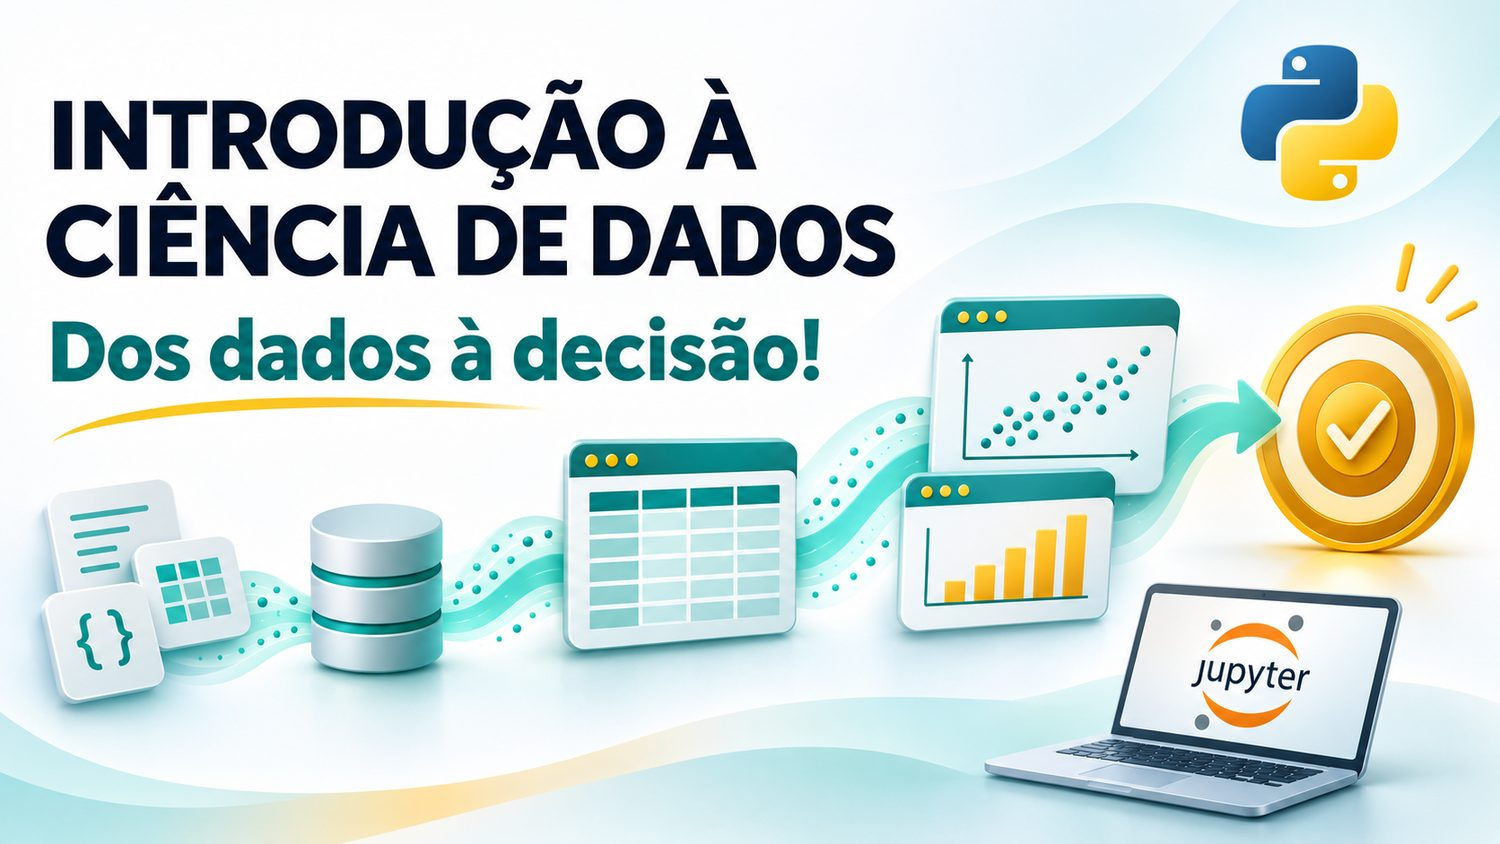

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_1_do_problema_a_decisao/05_Metodo_Cientifico_Amostragem_Inferencia.ipynb)

# Capítulo 5 – Método científico, amostragem e inferência

A palavra «ciência» em ciência de dados não é decorativa. Significa tratar cada conclusão como uma hipótese que os dados podem contrariar, e medir até que ponto se pode confiar nela. Este capítulo apresenta o método científico, liga-o ao CRISP-DM e mostra, por simulação, como se passa do que se vê numa amostra para o que se pode afirmar sobre o todo.

> **Objetivos:** descrever os passos do método científico e relacioná-los com as fases do CRISP-DM; formular hipóteses testáveis; distinguir população e amostra, parâmetro e estimativa; comparar formas de amostragem; quantificar a incerteza com um intervalo de confiança; ler o resultado de um teste de hipóteses; reconhecer práticas que enviesam a inferência.

**Pré-requisitos:** capítulos 1 a 4. Todas as contas são feitas por simulação, sem fórmulas de estatística.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_consultas(n=10_000, semente=42):
    """Gera marcações de consultas de uma clínica fictícia (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    antecedencia = rng.gamma(2.0, 9.0, n).round().clip(0, 90).astype(int)
    idade = rng.integers(18, 90, n)
    faltas_anteriores = rng.poisson(0.4, n)
    dia = rng.choice(["seg", "ter", "qua", "qui", "sex"], n)
    # A clínica envia mais lembretes por SMS a quem já faltou antes
    lembrete = rng.random(n) < 0.05 + 0.70 * (faltas_anteriores >= 1)
    z = (-3.7 + 0.05 * antecedencia + 1.0 * faltas_anteriores
         - 0.012 * (idade - 18) - 0.6 * lembrete + 0.3 * (dia == "seg"))
    faltou = rng.random(n) < 1 / (1 + np.exp(-z))
    return pd.DataFrame({"antecedencia_dias": antecedencia, "idade": idade,
                         "faltas_anteriores": faltas_anteriores, "dia_semana": dia,
                         "lembrete": lembrete, "faltou": faltou})


consultas = gerar_consultas()
consultas.head()

,antecedencia_dias,idade,faltas_anteriores,dia_semana,lembrete,faltou
0,19,55,2,qua,True,False
1,26,42,2,sex,True,False
2,17,48,0,ter,False,False
3,15,34,1,ter,False,False
4,28,43,0,sex,False,False


## O método científico

O método científico é uma forma disciplinada de aprender com a experiência. Não garante a verdade; garante que os erros podem ser encontrados.

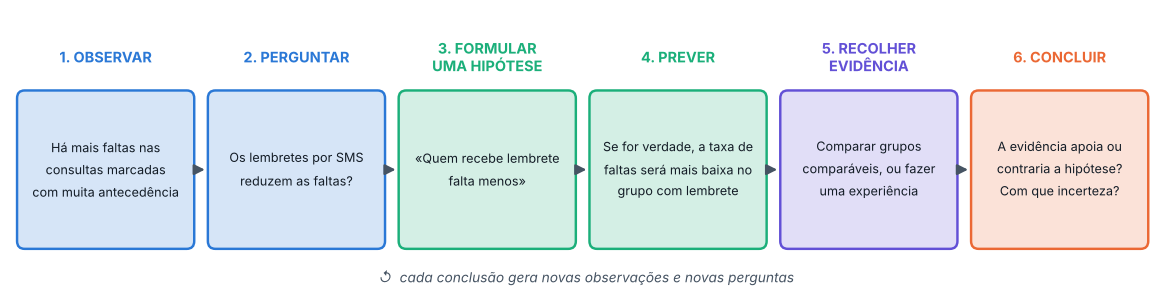

In [3]:
passos = [("1. OBSERVAR", "Há mais faltas nas\nconsultas marcadas\ncom muita antecedência", AZUL),
          ("2. PERGUNTAR", "Os lembretes por SMS\nreduzem as faltas?", AZUL),
          ("3. FORMULAR\nUMA HIPÓTESE", "«Quem recebe lembrete\nfalta menos»", VERDE),
          ("4. PREVER", "Se for verdade, a taxa de\nfaltas será mais baixa no\ngrupo com lembrete", VERDE),
          ("5. RECOLHER\nEVIDÊNCIA", "Comparar grupos\ncomparáveis, ou fazer\numa experiência", VIOLETA),
          ("6. CONCLUIR", "A evidência apoia ou\ncontraria a hipótese?\nCom que incerteza?", LARANJA)]

fig, ax = tela(15.2, 3.6, (13.5, 3.3))
for i, (nome, texto, cor) in enumerate(passos):
    x = 0.1 + i * 2.52
    caixa(ax, x, 0.55, 2.3, 2.0, texto, cor, 8.3)
    ax.text(x + 1.15, 3.0, nome, ha="center", va="center", fontweight="bold", color=cor, fontsize=9.5)
    if i < 5:
        seta(ax, (x + 2.33, 1.55), (x + 2.5, 1.55))
ax.text(7.6, 0.1, "↺  cada conclusão gera novas observações e novas perguntas", ha="center", style="italic", color="#465463", fontsize=9)
plt.show()

Três ideias sustentam o método:

- **Uma hipótese tem de poder ser contrariada.** «Os lembretes reduzem as faltas» pode ser desmentida pelos dados. «Os lembretes ajudam alguns pacientes de alguma forma» não pode, e por isso não serve.
- **A previsão faz-se antes de olhar para o resultado.** Quem decide o que procura depois de ver os dados encontra sempre alguma coisa.
- **A conclusão vem com a sua incerteza.** «Reduz as faltas» é uma frase incompleta. «Reduz entre 2 e 6 pontos percentuais» é uma conclusão.

### O método científico e o CRISP-DM

O CRISP-DM (capítulo 4) é o método científico adaptado a projetos de dados numa organização. As fases correspondem-se quase uma a uma.

| Método científico | CRISP-DM | O que se produz |
| --- | --- | --- |
| Observar e perguntar | Compreensão do negócio | Uma pergunta enquadrada, com a decisão que apoia |
| Formular uma hipótese | Compreensão do negócio e dos dados | Uma afirmação testável e a previsão que dela decorre |
| Recolher evidência | Compreensão e preparação dos dados | Dados adequados à pergunta, com os limites conhecidos |
| Analisar | Modelação | Uma estimativa, um teste ou um modelo |
| Concluir, com incerteza | Avaliação | Uma resposta, comparada com a linha de base |
| Comunicar e repetir | Implementação, e novo ciclo | Uma decisão, e as perguntas seguintes |

Os dois são **ciclos**. Num e noutro, voltar atrás é o funcionamento normal, e um resultado negativo («os dados não apoiam a hipótese») é um resultado.

A diferença está no ponto de chegada. O método científico procura **conhecimento**; o CRISP-DM procura uma **decisão melhor**. Por isso o CRISP-DM começa pelo negócio e acaba na implementação, duas fases que um cientista num laboratório não tem.

## População e amostra

Raramente se observa tudo o que interessa. Observa-se uma parte e tiram-se conclusões sobre o todo.

| Conceito | Definição | No caso da clínica |
| --- | --- | --- |
| **População** | Todos os casos sobre os quais queremos concluir | Todas as marcações da rede de clínicas |
| **Amostra** | Os casos que observámos | As marcações que analisámos |
| **Parâmetro** | Um valor da população, normalmente desconhecido | A verdadeira taxa de faltas |
| **Estimativa** | O valor calculado na amostra | A taxa de faltas da amostra |

Neste capítulo vamos fingir que as dez mil marcações são a população inteira. Assim conhecemos o parâmetro, e podemos ver quanto erram as amostras.

In [4]:
taxa_real = consultas["faltou"].mean()
rng = np.random.default_rng(0)

print(f"Parâmetro (população de {len(consultas)} marcações): {taxa_real:.1%}\n")
for tentativa in range(1, 6):
    amostra = consultas.sample(200, random_state=tentativa)
    print(f"Amostra {tentativa} (200 marcações): {amostra['faltou'].mean():.1%}")

Parâmetro (população de 10000 marcações): 7.3%

Amostra 1 (200 marcações): 8.0%
Amostra 2 (200 marcações): 7.5%
Amostra 3 (200 marcações): 7.0%
Amostra 4 (200 marcações): 7.5%
Amostra 5 (200 marcações): 9.0%


Cinco amostras, cinco estimativas, nenhuma igual ao parâmetro. A diferença entre a estimativa e o parâmetro chama-se **erro amostral**. Não é um engano: é a consequência inevitável de observar só uma parte.

### Quanto maior a amostra, menor o erro

Vamos repetir a experiência duas mil vezes para três tamanhos de amostra.

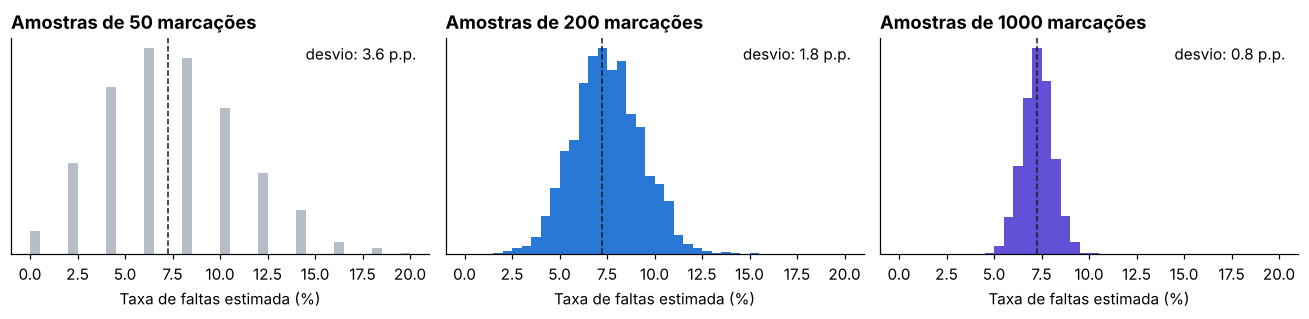

In [5]:
def muitas_amostras(n, repeticoes=2000):
    """Devolve a taxa de faltas de muitas amostras aleatórias de tamanho n."""
    faltou = consultas["faltou"].to_numpy()
    return np.array([rng.choice(faltou, n, replace=False).mean() for _ in range(repeticoes)]) * 100


fig, eixos = plt.subplots(1, 3, figsize=(12, 3), sharex=True)
for ax, n, cor in zip(eixos, [50, 200, 1000], [CINZA, AZUL, VIOLETA]):
    estimativas = muitas_amostras(n)
    ax.hist(estimativas, bins=np.arange(0, 20.5, 0.5), color=cor)
    ax.axvline(taxa_real * 100, color=TINTA, ls="--", lw=1)
    ax.set_title(f"Amostras de {n} marcações")
    ax.set_xlabel("Taxa de faltas estimada (%)")
    ax.text(0.97, 0.9, f"desvio: {estimativas.std():.1f} p.p.", transform=ax.transAxes, ha="right")
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Cada histograma mostra a **distribuição amostral**: o conjunto das estimativas que se podiam ter obtido. A linha tracejada é o parâmetro.

- Com 50 marcações, a estimativa pode ir de 0% a mais de 15%. Uma amostra destas quase não diz nada.
- Com 1 000 marcações, quase todas as estimativas ficam a menos de 2 pontos percentuais do parâmetro.

O desvio das estimativas chama-se **erro padrão**, e diminui com a raiz quadrada do tamanho da amostra: para reduzir o erro a metade é preciso uma amostra **quatro** vezes maior.

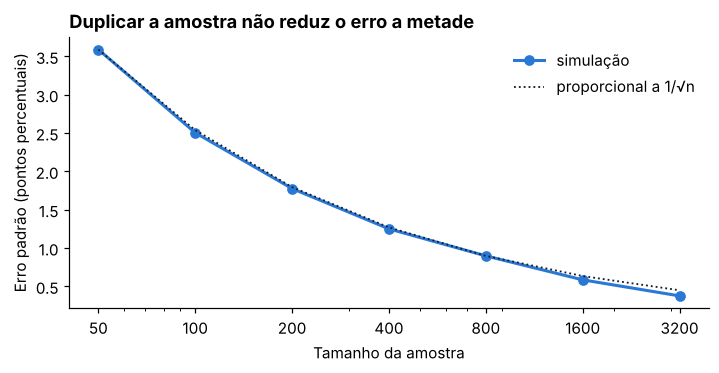

In [6]:
tamanhos = [50, 100, 200, 400, 800, 1600, 3200]
erros = [muitas_amostras(n, 800).std() for n in tamanhos]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(tamanhos, erros, color=AZUL, lw=2, marker="o", ms=6, label="simulação")
ax.plot(tamanhos, [erros[0] * np.sqrt(50 / n) for n in tamanhos], color=TINTA, ls=":", lw=1.2, label="proporcional a 1/√n")
ax.set_xscale("log")
ax.set_xticks(tamanhos, [str(n) for n in tamanhos])
ax.set_xlabel("Tamanho da amostra")
ax.set_ylabel("Erro padrão (pontos percentuais)")
ax.set_title("Duplicar a amostra não reduz o erro a metade")
ax.legend(frameon=False)
plt.show()

## Como se escolhe a amostra importa mais do que o tamanho

O erro amostral diminui com o tamanho. O **enviesamento** não. Uma amostra mal escolhida erra sempre para o mesmo lado, por maior que seja.

| Forma de amostragem | Como funciona | Quando usar |
| --- | --- | --- |
| **Aleatória simples** | Todos os casos têm a mesma probabilidade de ser escolhidos | Quando há uma lista completa da população |
| **Estratificada** | Divide-se a população em grupos e sorteia-se dentro de cada um, na proporção certa | Quando há grupos pequenos que não podem ficar de fora |
| **Por conveniência** | Usam-se os casos mais fáceis de obter | Só para explorar; nunca para concluir sobre a população |

Vamos comparar as três, sempre com 400 marcações. A amostra por conveniência usa as marcações mais fáceis de consultar: as que foram feitas há pouco tempo (com pouca antecedência).

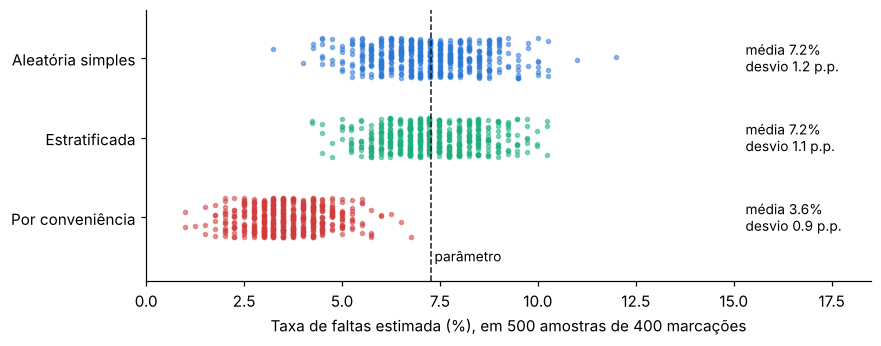

In [7]:
def aleatoria(n):
    return consultas.sample(n, random_state=int(rng.integers(1_000_000_000)))["faltou"].mean()


def estratificada(n):
    grupos = consultas["faltas_anteriores"].clip(upper=2)
    partes = [g.sample(round(n * len(g) / len(consultas)), random_state=int(rng.integers(1_000_000_000)))
              for _, g in consultas.groupby(grupos)]
    return pd.concat(partes)["faltou"].mean()


def conveniencia(n):
    recentes = consultas[consultas["antecedencia_dias"] <= 10]
    return recentes.sample(n, random_state=int(rng.integers(1_000_000_000)))["faltou"].mean()


resultados = {nome: np.array([funcao(400) for _ in range(500)]) * 100
              for nome, funcao in [("Aleatória simples", aleatoria), ("Estratificada", estratificada), ("Por conveniência", conveniencia)]}

fig, ax = plt.subplots(figsize=(8.5, 3.2))
for i, ((nome, valores), cor) in enumerate(zip(resultados.items(), [AZUL, VERDE, MAU])):
    ax.scatter(valores, np.full(len(valores), i) + rng.uniform(-0.25, 0.25, len(valores)), s=7, color=cor, alpha=0.5)
    ax.text(15.3, i, f"média {valores.mean():.1f}%\ndesvio {valores.std():.1f} p.p.", va="center", fontsize=9)
ax.axvline(taxa_real * 100, color=TINTA, ls="--", lw=1)
ax.text(taxa_real * 100 + 0.1, 2.55, "parâmetro", fontsize=9)
ax.set_yticks(range(3), list(resultados))
ax.set_xlim(0, 18.5)
ax.set_ylim(-0.6, 2.8)
ax.invert_yaxis()
ax.set_xlabel("Taxa de faltas estimada (%), em 500 amostras de 400 marcações")
plt.show()

- A amostra **aleatória** acerta em média, com alguma dispersão.
- A **estratificada** também acerta em média e tem um pouco menos de dispersão: ao garantir a proporção certa de pacientes com faltas anteriores, elimina uma fonte de acaso.
- A amostra **por conveniência** é muito consistente e está **errada**: subestima sempre a taxa, porque as marcações recentes são as que menos faltam. Aumentá-la só tornaria o erro mais convincente.

> **Uma amostra grande e enviesada é pior do que uma amostra pequena e aleatória:** a primeira dá uma resposta errada com muita confiança.

## Quantificar a incerteza: o intervalo de confiança

Na prática só temos **uma** amostra, e não conhecemos o parâmetro. Como saber quanto pode estar errada a nossa estimativa?

Uma técnica simples é a **reamostragem** (*bootstrap*): trata-se a amostra como se fosse a população e tiram-se dela muitas amostras do mesmo tamanho, com reposição. A dispersão dessas reamostras imita a dispersão que veríamos se pudéssemos repetir a recolha.

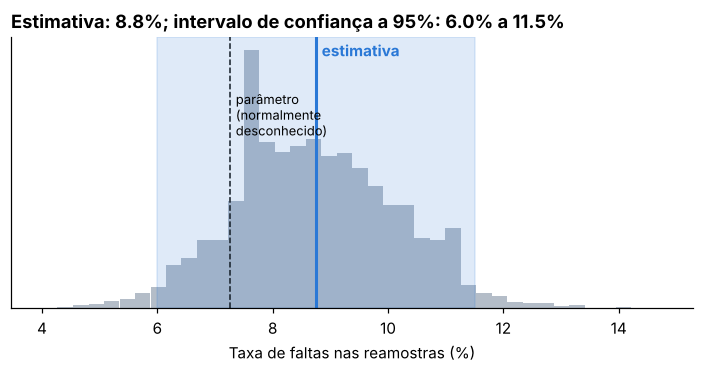

In [8]:
amostra = consultas.sample(400, random_state=9)["faltou"].to_numpy()
reamostras = np.array([rng.choice(amostra, len(amostra), replace=True).mean() for _ in range(5000)]) * 100
inferior, superior = np.percentile(reamostras, [2.5, 97.5])

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(reamostras, bins=40, color=CINZA)
ax.axvspan(inferior, superior, color=AZUL, alpha=0.15)
ax.axvline(amostra.mean() * 100, color=AZUL, lw=2)
ax.axvline(taxa_real * 100, color=TINTA, ls="--", lw=1)
topo = ax.get_ylim()[1]
ax.text(amostra.mean() * 100 + 0.1, topo * 0.93, "estimativa", color=AZUL, fontweight="bold")
ax.text(taxa_real * 100 + 0.1, topo * 0.80, "parâmetro\n(normalmente\ndesconhecido)", fontsize=8.5, va="top")
ax.set_xlabel("Taxa de faltas nas reamostras (%)")
ax.set_yticks([])
ax.set_title(f"Estimativa: {amostra.mean():.1%}; intervalo de confiança a 95%: {inferior:.1f}% a {superior:.1f}%")
plt.show()

O **intervalo de confiança a 95%** é a faixa que contém 95% das reamostras. Lê-se assim: «a taxa de faltas da população está provavelmente entre estes dois valores».

O que quer dizer «95%»? Que o método acerta 95 vezes em 100. A figura seguinte mostra cem amostras diferentes, cada uma com o seu intervalo.

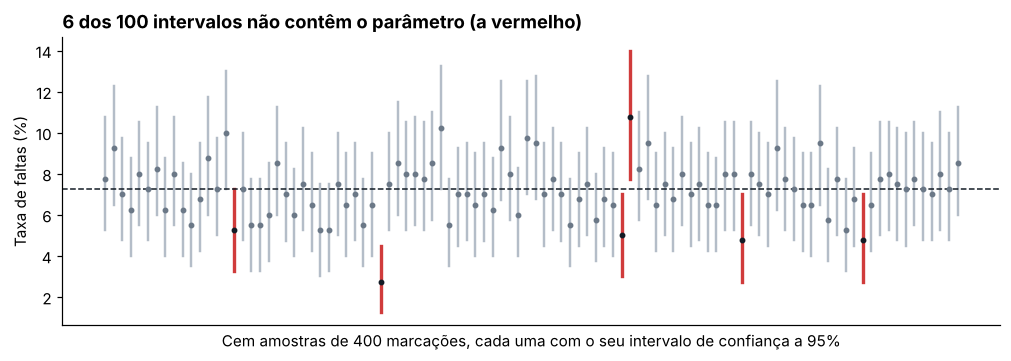

In [9]:
linhas = []
for i in range(100):
    a = consultas.sample(400, random_state=1000 + i)["faltou"].to_numpy()
    r = np.array([rng.choice(a, len(a), replace=True).mean() for _ in range(600)]) * 100
    linhas.append((a.mean() * 100, *np.percentile(r, [2.5, 97.5])))
linhas = np.array(linhas)
falha = (linhas[:, 1] > taxa_real * 100) | (linhas[:, 2] < taxa_real * 100)

fig, ax = plt.subplots(figsize=(11, 3.4))
for i, (centro, baixo, cima) in enumerate(linhas):
    cor = MAU if falha[i] else CINZA
    ax.plot([i, i], [baixo, cima], color=cor, lw=2.2 if falha[i] else 1.6)
    ax.scatter([i], [centro], s=8, color=TINTA if falha[i] else "#6b7887", zorder=3)
ax.axhline(taxa_real * 100, color=TINTA, ls="--", lw=1)
ax.set_xlabel("Cem amostras de 400 marcações, cada uma com o seu intervalo de confiança a 95%")
ax.set_ylabel("Taxa de faltas (%)")
ax.set_title(f"{int(falha.sum())} dos 100 intervalos não contêm o parâmetro (a vermelho)")
ax.set_xticks([])
plt.show()

Cerca de 95 dos 100 intervalos contêm o parâmetro. Os restantes falham, e quem os calculou não tem forma de o saber. É este o significado de 95% de confiança: uma taxa de acerto do método a longo prazo, e não uma garantia sobre um intervalo em particular.

> **Um número sem intervalo é meia resposta.** «A taxa de faltas é 7%» e «a taxa de faltas está entre 5% e 10%» levam a decisões diferentes.

## Testar uma hipótese

Voltemos à pergunta do capítulo 2: os lembretes reduzem as faltas? Vimos que a comparação tem de ser feita entre pacientes parecidos, por isso olhamos só para quem tem exatamente **uma** falta anterior.

In [10]:
grupo = consultas[consultas["faltas_anteriores"] == 1]
com = grupo[grupo["lembrete"]]["faltou"].to_numpy()
sem = grupo[~grupo["lembrete"]]["faltou"].to_numpy()
diferenca = (sem.mean() - com.mean()) * 100

print(f"Sem lembrete: {sem.mean():.1%} de faltas ({len(sem)} marcações)")
print(f"Com lembrete: {com.mean():.1%} de faltas ({len(com)} marcações)")
print(f"Diferença observada: {diferenca:.1f} pontos percentuais")

Sem lembrete: 12.0% de faltas (656 marcações)
Com lembrete: 7.5% de faltas (2032 marcações)
Diferença observada: 4.5 pontos percentuais


Há uma diferença. Mas vimos que amostras diferentes dão valores diferentes só por acaso. A pergunta do teste é: **uma diferença deste tamanho podia aparecer por acaso, se o lembrete não fizesse nada?**

Para responder, constrói-se um mundo em que o lembrete não faz nada. Chama-se a isto a **hipótese nula**. Se o lembrete é irrelevante, a etiqueta «com lembrete» podia ter calhado a qualquer paciente. Baralhamos as etiquetas milhares de vezes e vemos que diferenças aparecem.

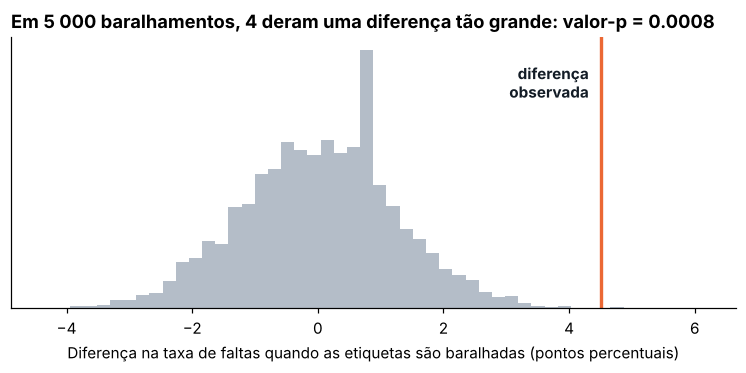

In [11]:
todos = np.concatenate([com, sem])
baralhadas = []
for _ in range(5000):
    rng.shuffle(todos)
    baralhadas.append((todos[len(com):].mean() - todos[:len(com)].mean()) * 100)
baralhadas = np.array(baralhadas)
valor_p = (baralhadas >= diferenca).mean()

fig, ax = plt.subplots(figsize=(8.5, 3.2))
ax.hist(baralhadas, bins=50, color=CINZA)
ax.axvline(diferenca, color=LARANJA, lw=2.2)
ax.text(diferenca - 0.2, ax.get_ylim()[1] * 0.9, "diferença\nobservada", color=TINTA, ha="right", va="top", fontweight="bold")
ax.set_xlabel("Diferença na taxa de faltas quando as etiquetas são baralhadas (pontos percentuais)")
ax.set_yticks([])
ax.set_title(f"Em 5 000 baralhamentos, {int((baralhadas >= diferenca).sum())} deram uma diferença tão grande: valor-p = {valor_p:.4f}")
plt.show()

O histograma mostra as diferenças que o acaso produz sozinho. A diferença observada fica muito para lá do que o acaso costuma dar.

O **valor-p** é a fração de baralhamentos que deu uma diferença pelo menos tão grande como a observada. Um valor-p pequeno quer dizer que o acaso, sozinho, raramente produz um resultado destes, e por isso rejeita-se a hipótese nula. A convenção habitual é rejeitar abaixo de 0,05.

### O que o valor-p não diz

- **Não é a probabilidade de a hipótese ser verdadeira.** É a probabilidade de ver estes dados *se* a hipótese nula for verdadeira.
- **Não mede a importância.** Com muitos dados, uma diferença irrelevante torna-se «significativa». Olha sempre para o tamanho do efeito e para o seu intervalo de confiança.
- **Não prova causalidade.** Neste caso os lembretes não foram sorteados (capítulo 2): pode haver outra diferença entre os grupos. O teste só exclui o acaso.

Um teste pode errar de duas maneiras, que são as mesmas do capítulo 3:

| | A hipótese nula é verdadeira | A hipótese nula é falsa |
| --- | --- | --- |
| **O teste rejeita-a** | Falso alarme (erro do tipo I) | Decisão certa |
| **O teste não a rejeita** | Decisão certa | Efeito não detetado (erro do tipo II) |

## Como se engana quem procura demasiado

Se o limiar é 0,05, um efeito inexistente passa no teste uma vez em vinte. Quem testar vinte hipóteses falsas encontra, em média, uma «descoberta».

A célula seguinte cria 40 variáveis completamente aleatórias (o signo do paciente, o último algarismo do telefone…) e testa se cada uma está associada às faltas.

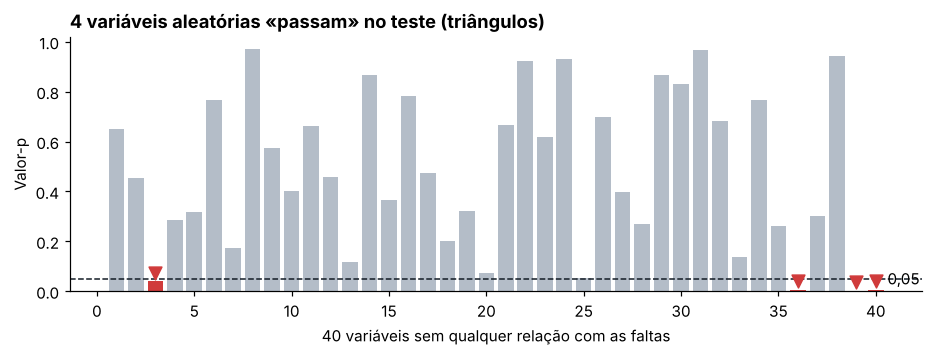

In [12]:
rng = np.random.default_rng(4)
faltou = consultas["faltou"].to_numpy()
valores_p = []
for _ in range(40):
    etiqueta = rng.random(len(faltou)) < 0.5                    # uma variável sem relação nenhuma com as faltas
    observada = abs(faltou[etiqueta].mean() - faltou[~etiqueta].mean())
    nulas = []
    for _ in range(400):
        baralhada = rng.permutation(etiqueta)
        nulas.append(abs(faltou[baralhada].mean() - faltou[~baralhada].mean()))
    valores_p.append((np.array(nulas) >= observada).mean())
valores_p = np.array(valores_p)

fig, ax = plt.subplots(figsize=(10, 3))
cores = [MAU if p < 0.05 else CINZA for p in valores_p]
ax.bar(range(1, 41), valores_p, color=cores)
abaixo = valores_p < 0.05
ax.scatter(np.arange(1, 41)[abaixo], valores_p[abaixo] + 0.035, marker="v", s=70, color=MAU, zorder=3)
ax.axhline(0.05, color=TINTA, ls="--", lw=1)
ax.text(40.6, 0.05, "0,05", va="center")
ax.set_xlabel("40 variáveis sem qualquer relação com as faltas")
ax.set_ylabel("Valor-p")
ax.set_title(f"{int((valores_p < 0.05).sum())} variáveis aleatórias «passam» no teste (triângulos)")
plt.show()

Nenhuma destas variáveis tem relação com as faltas, e mesmo assim algumas ficam abaixo de 0,05. Quem só mostrasse essas teria um resultado «estatisticamente significativo» e completamente falso.

### Cinco hábitos que reduzem o viés na inferência

1. **Escreve a hipótese antes de olhar para os dados.** Uma hipótese formulada depois de ver o resultado não foi testada.
2. **Conta quantas comparações fizeste**, e diz quantas. Vinte testes com um resultado positivo não são o mesmo que um teste com um resultado positivo.
3. **Compara grupos comparáveis.** Se puderes, sorteia quem recebe a intervenção.
4. **Apresenta o tamanho do efeito com o seu intervalo**, e não apenas «é significativo».
5. **Confirma com dados novos.** Uma descoberta feita numa amostra confirma-se noutra. Se desaparecer, era acaso.

## Exercícios

### `Exercício 1` – Hipótese testável?

Indica quais destas hipóteses podem ser contrariadas pelos dados, e reescreve as que não podem:

1. «Os pacientes mais novos faltam mais do que os mais velhos.»
2. «O ambiente da sala de espera influencia a experiência dos pacientes.»
3. «Telefonar na véspera reduz as faltas em pelo menos dois pontos percentuais.»
4. «Às segundas-feiras as coisas correm pior.»

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Testável.
2. Não testável: «influencia» e «experiência» não estão definidos. Reescrita: «Os pacientes das clínicas com sala de espera renovada dão avaliações de satisfação mais altas do que os das restantes.»
3. Testável, e a melhor das quatro: diz a direção e o tamanho mínimo do efeito.
4. Não testável. Reescrita: «A taxa de faltas à segunda-feira é mais alta do que nos outros dias úteis.»

</details>

### `Exercício 2` – O tamanho da amostra

Queres estimar a taxa de faltas com um erro padrão de cerca de 0,5 pontos percentuais. Usa a função `muitas_amostras` para descobrir de que tamanho tem de ser a amostra.

In [13]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for n in [1000, 2000, 2500, 3000]:
    print(n, round(muitas_amostras(n, 600).std(), 2))
```

São precisas cerca de 2 000 a 2 500 marcações. Com 400 o erro padrão era de cerca de 1,3 pontos; para o reduzir a menos de metade foi preciso mais do que quintuplicar a amostra.

</details>

### `Exercício 3` – Que amostragem é esta?

Classifica cada caso e indica se a amostra pode estar enviesada:

1. Um jornal publica um inquérito no seu sítio e analisa as 12 000 respostas recebidas.
2. Uma fábrica inspeciona uma peça em cada cem, escolhida por sorteio.
3. Um estudo sobre salários sorteia 200 pessoas em cada região do país, na proporção da população de cada região.
4. Um investigador entrevista os primeiros 50 clientes que entram numa loja à segunda-feira de manhã.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Por conveniência (quem responde escolhe-se a si próprio). Enviesada, apesar das 12 000 respostas.
2. Aleatória simples.
3. Estratificada por região.
4. Por conveniência. Enviesada: quem faz compras à segunda de manhã não representa os clientes da loja.

</details>

### `Exercício 4` – Um teste teu

Testa se a taxa de faltas à segunda-feira é diferente da dos outros dias. Formula a hipótese nula, calcula a diferença observada, baralha as etiquetas e indica o valor-p e a tua conclusão.

In [14]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
segunda = (consultas["dia_semana"] == "seg").to_numpy()
faltou = consultas["faltou"].to_numpy()
observada = faltou[segunda].mean() - faltou[~segunda].mean()

nulas = []
for _ in range(2000):
    b = rng.permutation(segunda)
    nulas.append(faltou[b].mean() - faltou[~b].mean())
valor_p = (np.abs(nulas) >= abs(observada)).mean()
print(f"Diferença: {observada * 100:.1f} pontos percentuais; valor-p: {valor_p:.3f}")
```

Hipótese nula: o dia da semana não tem relação com as faltas. A diferença observada é de cerca de 2 pontos percentuais e o valor-p fica muito abaixo de 0,05, por isso rejeita-se a hipótese nula. O teste diz que a diferença dificilmente se deve ao acaso; não diz porquê.

</details>

## Verifica o que aprendeste

- [ ] Sei enumerar os passos do método científico e ligá-los às fases do CRISP-DM.
- [ ] Sei distinguir uma hipótese testável de uma afirmação vaga.
- [ ] Sei distinguir população e amostra, parâmetro e estimativa.
- [ ] Sei explicar porque o erro amostral diminui com o tamanho da amostra e o enviesamento não.
- [ ] Sei comparar a amostragem aleatória, a estratificada e a por conveniência.
- [ ] Sei calcular e interpretar um intervalo de confiança por reamostragem.
- [ ] Sei explicar o que é, e o que não é, um valor-p.
- [ ] Sei porque testar muitas hipóteses produz falsas descobertas.

## Leitura recomendada

- https://en.wikipedia.org/wiki/Scientific_method
- https://en.wikipedia.org/wiki/Sampling_(statistics)
- https://en.wikipedia.org/wiki/Bootstrapping_(statistics)
- https://en.wikipedia.org/wiki/Permutation_test
- https://en.wikipedia.org/wiki/Multiple_comparisons_problem